# 05 · Inferencia sobre `test.csv`

**Proyecto #2 – Pipeline de Machine Learning · Predict Future Sales (Kaggle)**

Último paso: usar el **pipeline completo** (`models/full_pipeline.pkl`, preprocesamiento + modelo
ganador del notebook 04) para predecir las ventas de **noviembre 2015 (`date_block_num = 34`)** de
los 214,200 pares tienda-producto de `test.csv`, un mes que el modelo nunca vio.

| Punto del enunciado | Sección |
|---|---|
| 4.a Usar el pipeline completo (`.pkl`) para predecir un dataset no visto: `test.csv` | 1, 2 |
| 4.b `.csv` con las columnas `ID` e `item_cnt_month` (formato de envío de Kaggle) | 3, 4 |

No hay ninguna preparación manual de variables: `test.csv` entra **crudo** al pipeline (solo se le
agrega el mes a predecir). Los lags del mes 34 se obtienen de los meses 33, 32, 31, … que el pipeline
lleva guardados.

## 0. Configuración

In [1]:
import os

os.environ["LOGURU_LEVEL"] = "WARNING"

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from predict_future_sales.config import MODELS_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR, REPORTS_DIR
import predict_future_sales.features as pf
from predict_future_sales.plots import COLOR_ACCENT, COLOR_MAIN, COLOR_MUTED, save_fig, set_style

set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
SUBMISSION_PATH = PROCESSED_DATA_DIR / "submission.csv"

## 1. Cargar el pipeline completo y el dataset de prueba

In [2]:
full_pipeline = joblib.load(MODELS_DIR / "full_pipeline.pkl")
best = json.loads((REPORTS_DIR / "best_model.json").read_text(encoding="utf-8"))
print("Pasos del pipeline:", [name for name, _ in full_pipeline.steps])
print(f"Modelo final: {best['modelo']} ({best['clase']}) · RMSE validación {best['rmse_validacion']} · entrenado con {best['entrenamiento_final']}")

test = pd.read_csv(RAW_DATA_DIR / "test.csv")
sample_submission = pd.read_csv(RAW_DATA_DIR / "sample_submission.csv")
print(f"test.csv: {test.shape[0]:,} filas · columnas {list(test.columns)}")
print(f"Tiendas: {test.shop_id.nunique()} · productos: {test.item_id.nunique():,} · ID únicos: {test.ID.is_unique}")
test.head()

Pasos del pipeline: ['history', 'map_city', 'map_shop_type', 'map_category_group', 'drop_keys', 'missing_indicator', 'num_imputer', 'cat_imputer', 'onehot', 'mean_encoder', 'outliers', 'log', 'scaler', 'float32', 'model']
Modelo final: Random Forest #2 (RandomForestRegressor) · RMSE validación 0.8096 · entrenado con meses 0-33
test.csv: 214,200 filas · columnas ['ID', 'shop_id', 'item_id']
Tiendas: 42 · productos: 5,100 · ID únicos: True


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


## 2. Predicción

Se agrega `date_block_num = 34` y se pasa al pipeline. Las predicciones se recortan a **[0, 20]**,
el mismo rango del objetivo con el que se entrenó y con el que Kaggle evalúa.

In [3]:
X_test = test.assign(date_block_num=pf.TEST_BLOCK)[pf.KEYS]
raw_pred = full_pipeline.predict(X_test)
pred = np.clip(raw_pred, *pf.TARGET_CLIP)
print(f"Predicciones fuera de [0, 20] antes del recorte: {(raw_pred < 0).sum():,} negativas, {(raw_pred > 20).sum():,} > 20")
pd.Series(pred).describe().to_frame("item_cnt_month predicho").T

Predicciones fuera de [0, 20] antes del recorte: 0 negativas, 0 > 20


,count,mean,std,min,25%,50%,75%,max
item_cnt_month predicho,"214,200.0000",0.2995,0.8229,0.0021,0.0219,0.0844,0.2570,19.3586


## 3. Archivo de envío (formato Kaggle)

In [4]:
submission = pd.DataFrame({"ID": test["ID"], "item_cnt_month": pred})

# Validaciones del formato
checks = {
    "mismas columnas que sample_submission.csv": list(submission.columns) == list(sample_submission.columns),
    "214,200 filas (una por par de test.csv)": len(submission) == len(test) == len(sample_submission),
    "ID únicos y en el mismo orden que test.csv": submission.ID.is_unique and submission.ID.equals(test.ID),
    "mismos ID que sample_submission.csv": set(submission.ID) == set(sample_submission.ID),
    "sin valores faltantes": not submission.isna().any().any(),
    "predicciones dentro de [0, 20]": submission.item_cnt_month.between(0, 20).all(),
}
assert all(checks.values()), checks

submission.to_csv(SUBMISSION_PATH, index=False)
print(f"Guardado: data/processed/{SUBMISSION_PATH.name} ({SUBMISSION_PATH.stat().st_size / 1e6:.1f} MB)")
display(pd.Series(checks, name="OK").to_frame())
pd.read_csv(SUBMISSION_PATH).head()

Guardado: data/processed/submission.csv (5.9 MB)


,OK
mismas columnas que sample_submission.csv,True
"214,200 filas (una por par de test.csv)",True
ID únicos y en el mismo orden que test.csv,True
mismos ID que sample_submission.csv,True
sin valores faltantes,True
"predicciones dentro de [0, 20]",True


,ID,item_cnt_month
0,0,0.5374
1,1,0.3300
2,2,0.9724
3,3,0.4277
4,4,3.7297


## 4. Revisión de coherencia de las predicciones

No se conoce la venta real de noviembre 2015, pero se puede revisar que las predicciones sean
**coherentes con la historia**: se comparan con las ventas reales de los mismos pares en octubre 2015
(mes 33), por segmento de novedad y por tienda.

In [5]:
history = full_pipeline.named_steps["history"].transform(X_test)  # variables crudas del mes 34
review = test.assign(pred=pred, oct_2015=history["cnt_lag_1"].to_numpy(),
                     segmento=np.select([history.item_is_new == 1, history.pair_is_new == 1],
                                        ["producto nuevo", "producto conocido, par nuevo"], "par con historia"))
seg = review.groupby("segmento").agg(pares=("ID", "size"), venta_oct_2015=("oct_2015", "mean"),
                                     prediccion_nov_2015=("pred", "mean"))
seg["% de pares"] = seg.pares / len(review) * 100
seg

,pares,venta_oct_2015,prediccion_nov_2015,% de pares
segmento,,,,
par con historia,111471,0.4912,0.4009,52.0406
"producto conocido, par nuevo",87483,0.0000,0.0693,40.8417
producto nuevo,15246,0.0000,0.8793,7.1176


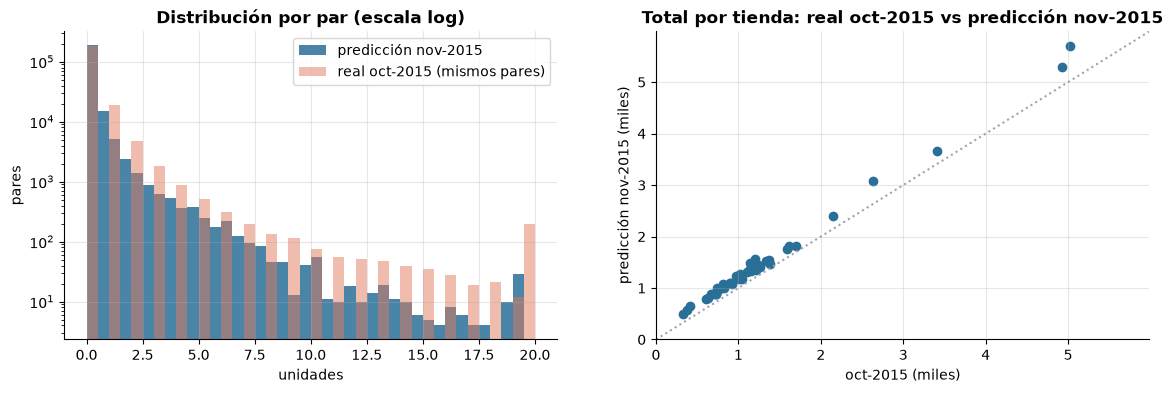

Total predicho nov-2015: 64,156 unidades · real oct-2015 de los mismos pares: 54,760
Correlación entre tiendas (oct real vs nov predicho): 0.998


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.linspace(0, 20, 41)
axes[0].hist(review.pred, bins=bins, color=COLOR_MAIN, alpha=0.85, label="predicción nov-2015")
axes[0].hist(review.oct_2015, bins=bins, color=COLOR_ACCENT, alpha=0.5, label="real oct-2015 (mismos pares)")
axes[0].set_yscale("log")
axes[0].set(title="Distribución por par (escala log)", xlabel="unidades", ylabel="pares")
axes[0].legend()

by_shop = review.groupby("shop_id").agg(oct_2015=("oct_2015", "sum"), pred=("pred", "sum"))
axes[1].scatter(by_shop.oct_2015 / 1e3, by_shop.pred / 1e3, color=COLOR_MAIN)
lim = [0, by_shop.max().max() / 1e3 * 1.05]
axes[1].plot(lim, lim, color=COLOR_MUTED, ls=":")
axes[1].set(title="Total por tienda: real oct-2015 vs predicción nov-2015", xlabel="oct-2015 (miles)",
            ylabel="predicción nov-2015 (miles)", xlim=lim, ylim=lim)
save_fig(fig, "p2_05a_predicciones_test")
plt.show()
print(f"Total predicho nov-2015: {review.pred.sum():,.0f} unidades · real oct-2015 de los mismos pares: {review.oct_2015.sum():,.0f}")
print(f"Correlación entre tiendas (oct real vs nov predicho): {by_shop.oct_2015.corr(by_shop.pred):.3f}")

**Interpretación.** Las predicciones son **coherentes con la historia**.

- **Distribución.** El modelo no generó ningún valor fuera de [0, 20] (el recorte no tuvo que actuar). La media predicha es 0.30 unidades por par y la mediana 0.08: igual que en el histórico, la mayoría de los pares vende muy poco y unos pocos concentran las ventas (máximo 19.4).
- **Por segmento** (mismas proporciones que encontró el EDA: 52.0 % / 40.8 % / 7.1 %):
  - **Pares con historia:** se predicen 0.40 unidades de media frente a 0.49 reales en octubre. El modelo modera los valores altos del último mes, porque un par que vendió mucho en octubre tiende a vender menos al mes siguiente (ciclo de vida del producto y tendencia de −1.8 % mensual del EDA).
  - **Pares nuevos de productos conocidos:** 0.07 de media. Casi nada, que es el comportamiento que el modelo vio en validación (0.054 reales).
  - **Productos nuevos:** 0.88 de media, el valor más alto de los tres segmentos. Refleja el **efecto lanzamiento**: en validación los productos nuevos fueron el segmento con mayor venta media (0.56).
- **Total.** Se pronostican **64,156 unidades** para noviembre 2015 frente a 54,760 reales de los mismos pares en octubre (+17 %). Ese aumento lo explican casi por completo los productos nuevos (~13,400 unidades que en octubre no existían), porque los pares con historia bajan. Como referencia, noviembre vendió 2.9 % y 6.6 % más que octubre en 2013 y 2014.
- **Por tienda.** El total predicho por tienda tiene una correlación de **0.998** con el total real de octubre: el modelo conserva el tamaño relativo de cada tienda.

## 5. Conclusiones

1. El **pipeline completo** (`models/full_pipeline.pkl`: 14 pasos de preprocesamiento + Random Forest) se cargó y se aplicó directamente sobre `test.csv` **crudo**: no hubo preparación manual de variables, solo se agregó el mes a predecir (34). Los lags de noviembre 2015 salen de los meses 33, 32, 31…, sin fuga de información.
2. Se generó **`data/processed/submission.csv`** con las columnas **`ID, item_cnt_month`**: 214,200 filas, los mismos ID y columnas que `sample_submission.csv`, sin faltantes y con valores en [0, 20]. Está listo para subirse a Kaggle.
3. Las predicciones son coherentes con la historia por segmento y por tienda (correlación 0.998 con el total real de octubre). Los productos nuevos reciben un nivel de venta propio gracias a las banderas y la información de categoría del modelo.
4. El RMSE esperado es el de validación del notebook 04 (**0.81**). El RMSE real del mes 34 solo se conoce al subir el archivo a la competencia, porque Kaggle no publica las ventas reales de noviembre 2015.